# RoadScan Project Experiments
Saved detectors are restored before evaluation. The unfinished augmentation experiment resumes from its checkpoint. The classifier and remaining analyses follow.

In [1]:
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install',
    'rfdetr[train]==1.11.2', 'transformers==5.1.0', 'pycocotools==2.0.11',
    'numpy', 'pandas', 'Pillow', 'matplotlib', 'scikit-learn', 'ImageHash'])
print('If imports fail after installation, restart the kernel and continue below.')


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 788.9/788.9 kB 15.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 104.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 58.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 68.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.2/983.2 kB 22.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 769.6/769.6 kB 20.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 65.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.7/604.7 kB 9.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 118.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 92.8 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2
  Attempting uninstall: tokenizers
    Found existing installation: tokenizers 0.23.1
  

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


If imports fail after installation, restart the kernel and continue below.


## Experiment Settings
Restore saved experiments from the attached backup and use the original road image dataset.

In [2]:
from pathlib import Path
import os

# Leave paths blank to discover attached Kaggle datasets automatically.
DATA_SOURCE = ''
BACKUP_SOURCE = ''
OUTPUT_ROOT = Path('/kaggle/working/RoadScan_20Epoch_Experiments')
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

HELD_OUT_COUNTRY = 'India'
EPOCHS = 20
SEED = 42
RF_BATCH_SIZE = 4
RF_GRAD_ACCUM_STEPS = 4
NUM_WORKERS = 0
CPU_THREADS = 4
CPU_TIMING_IMAGES = 20
NEAR_DUPLICATE_HAMMING = 4
VALIDATION_FRACTION = 0.10
TEST_FRACTION = 0.10
SAUDI_LABELS_HUMAN_VERIFIED = False
TEAM_LOCAL_MANIFEST = ''
DUPLICATE_PAIRS_CSV = ''
assert EPOCHS == 20
assert 0 <= NEAR_DUPLICATE_HAMMING <= 4


In [3]:
import collections, contextlib, csv, gc, hashlib, io, json, math, platform
import random, shutil, time, zipfile
import numpy as np
import pandas as pd
from PIL import Image, ImageOps, ImageDraw
import matplotlib.pyplot as plt
from IPython.display import display
CLASS_NAMES = ['longitudinal_crack','transverse_crack','alligator_crack','pothole']
CODES = ['D00','D10','D20','D40']
NC, MAX_DET, CONF_FLOOR = 4, 300, 0.001
EXTS = {'.jpg','.jpeg','.png','.bmp','.webp','.tif','.tiff'}
random.seed(SEED); np.random.seed(SEED)
OUTPUT_ROOT = OUTPUT_ROOT.expanduser().resolve()
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

def save_json(path, obj):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix+'.tmp')
    tmp.write_text(json.dumps(obj, indent=2, ensure_ascii=False, allow_nan=False), encoding='utf-8')
    tmp.replace(path)

def file_hash(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda:f.read(1024*1024), b''): h.update(b)
    return h.hexdigest()

def object_hash(obj):
    return hashlib.sha256(json.dumps(obj,sort_keys=True,ensure_ascii=False).encode()).hexdigest()

def country_name(value):
    key = str(value).strip().lower().replace(' ','_')
    if key in {'china','china_drone','china_motorbike'}: return 'China'
    return {'india':'India','japan':'Japan','norway':'Norway','czech':'Czech',
        'czech_republic':'Czech','united_states':'United_States','usa':'United_States'}.get(key, str(value).strip())
HELD_OUT_COUNTRY = country_name(HELD_OUT_COUNTRY)


## Data Validation
Verify source images, annotations, and the country holdout partition.

In [4]:
def locate_dataset(source):
    if not source:
        candidates = []
        bases = [Path.cwd(), Path('/content'), Path('/kaggle/input')]
        for base in bases:
            if base.exists():
                candidates.extend(p.parent for p in base.rglob('manifest.jsonl')
                    if (p.parent/'images/train').is_dir() and (p.parent/'labels/train').is_dir())
        candidates = sorted(set(p.resolve() for p in candidates))
        if not candidates:
            archives = []
            for base in bases:
                if not base.exists():
                    continue
                for path in base.rglob('*.zip'):
                    with zipfile.ZipFile(path) as z:
                        names = z.namelist()
                        if any(n.endswith('manifest.jsonl') for n in names) and any('/images/train/' in '/' + n for n in names):
                            archives.append(path.resolve())
            archives = sorted(set(archives))
            if len(archives) == 1:
                return locate_dataset(str(archives[0]))
        if len(candidates) != 1:
            raise ValueError(f'Set DATA_SOURCE explicitly to the dataset or ZIP. Candidates: {candidates}')
        return candidates[0]
    source = Path(source).expanduser().resolve()
    if not source.exists(): raise FileNotFoundError(source)
    if source.is_file():
        if source.suffix.lower() != '.zip': raise ValueError('Expected a dataset folder or ZIP.')
        dest = OUTPUT_ROOT/'extracted'/file_hash(source)[:16]
        marker = dest/'extraction_complete.json'
        if not marker.exists():
            dest.mkdir(parents=True, exist_ok=True)
            with zipfile.ZipFile(source) as archive:
                for member in archive.infolist():
                    if not (dest/member.filename).resolve().is_relative_to(dest.resolve()):
                        raise ValueError('Unsafe ZIP path')
                archive.extractall(dest)
            save_json(marker, {'source_sha256':file_hash(source)})
        source = dest
    roots = [source] if (source/'manifest.jsonl').is_file() and (source/'images/train').is_dir() else [
        p.parent for p in source.rglob('manifest.jsonl') if (p.parent/'images/train').is_dir()]
    if len(roots) != 1: raise ValueError(f'Expected one dataset root, got {roots}')
    return roots[0]

def read_yolo(path):
    rows = []
    for line in path.read_text(encoding='utf-8-sig').splitlines():
        if not line.strip(): continue
        values = np.asarray([float(v) for v in line.split()])
        if len(values)!=5 or not np.isfinite(values).all(): raise ValueError(f'Invalid YOLO label: {path}')
        c,x,y,w,h = values
        if c != int(c) or not 0<=c<NC or not (0<=x<=1 and 0<=y<=1 and 0<w<=1 and 0<h<=1):
            raise ValueError(f'Invalid YOLO class/coordinates: {path}')
        if min(x-w/2,y-h/2)<-1e-4 or max(x+w/2,y+h/2)>1.0001:
            raise ValueError(f'Out-of-image YOLO box: {path}')
        rows.append(values)
    return np.asarray(rows,dtype=float).reshape(-1,5)

def path_inside(root, rel):
    p = (root/str(rel)).resolve()
    if not p.is_relative_to(root.resolve()): raise ValueError(f'Path outside manifest folder: {rel}')
    if not p.is_file(): raise FileNotFoundError(p)
    return p

def phash64(image):
    # DCT perceptual hash implemented with NumPy; 32x32 -> low-frequency 8x8.
    pixels = np.asarray(image.convert('L').resize((32,32),Image.Resampling.LANCZOS),dtype=float)
    k = np.arange(8)[:,None]; n = np.arange(32)[None,:]
    dct = np.cos(np.pi/32*(n+0.5)*k)
    block = dct@pixels@dct.T
    bits = (block>np.median(block)).ravel()
    return sum(int(bit)<<i for i,bit in enumerate(bits))

DATA_ROOT = locate_dataset(DATA_SOURCE)
raw_rows = [json.loads(s) for s in (DATA_ROOT/'manifest.jsonl').read_text(encoding='utf-8').splitlines() if s.strip()]
dataset_metadata = json.loads((DATA_ROOT/'dataset_version.json').read_text(encoding='utf-8')) if (DATA_ROOT/'dataset_version.json').exists() else {}
if dataset_metadata.get('class_names',CLASS_NAMES)!=CLASS_NAMES:
    raise ValueError('Dataset class order differs from D00/D10/D20/D40')
quarantine_path = DATA_ROOT/'training_quarantine.csv'
blocked = set(pd.read_csv(quarantine_path)['image'].astype(str)) if quarantine_path.exists() else set()
manifest_images = [r['image'] for r in raw_rows]
if len(manifest_images)!=len(set(manifest_images)): raise ValueError('Duplicate manifest image path')
disk_images = {p.relative_to(DATA_ROOT).as_posix() for p in (DATA_ROOT/'images').rglob('*') if p.suffix.lower() in EXTS}
if set(manifest_images)!=disk_images: raise ValueError('Manifest does not match all image files')
if TEAM_LOCAL_MANIFEST:
    team_file = Path(TEAM_LOCAL_MANIFEST).expanduser().resolve()
    for r in [json.loads(s) for s in team_file.read_text(encoding='utf8').splitlines() if s.strip()]:
        raw_rows.append(dict(r,domain='team_local',_root=str(team_file.parent)))

records = []; quarantined = []
for index,r in enumerate(raw_rows):
    if '_root' not in r and r['image'] in blocked:
        quarantined.append(r['image']); continue
    root = Path(r.get('_root',DATA_ROOT))
    image = path_inside(root,r['image']); label = path_inside(root,r['label'])
    yolo = read_yolo(label)
    with Image.open(image) as im:
        if int(im.getexif().get(274,1)) not in (0,1): raise ValueError('Normalize EXIF and boxes before use')
        rgb = im.convert('RGB'); width,height = rgb.size
        pixel_hash = hashlib.sha256(str(rgb.size).encode()+rgb.tobytes()).hexdigest()
        perceptual = phash64(rgb)
    truth = yolo.copy()
    if len(truth):
        truth[:,1:3] = (yolo[:,1:3]-yolo[:,3:]/2)*[width,height]
        truth[:,3:5] = (yolo[:,1:3]+yolo[:,3:]/2)*[width,height]
    domain = r.get('domain','rdd')
    country = country_name(r.get('country','')) if domain=='rdd' else 'Saudi' if domain!='team_local' else 'Team_local'
    if domain=='rdd' and not country: raise ValueError('RDD country labels are required; never infer from hashed filenames')
    records.append(dict(image=str(image),label=str(label),key=f'{domain}:{r["image"]}',
        original_split=r.get('split'),domain=domain,country=country,scene_group=r.get('scene_group'),
        width=width,height=height,truth=truth,sha256=file_hash(image),label_sha256=file_hash(label),
        pixel_hash=pixel_hash,phash=perceptual))
    if (index+1)%1000==0: print('Checked',index+1,'images')
print('Dataset:',DATA_ROOT)
display(pd.crosstab(pd.Series([r['country'] for r in records],name='country'),pd.Series([r['original_split'] for r in records],name='original_split')))


Checked 1000 images
Checked 2000 images
Checked 3000 images
Checked 4000 images
Checked 5000 images
Checked 6000 images
Checked 7000 images
Checked 8000 images
Dataset: /kaggle/input/datasets/ramaabdulsalam/roadscan-dataset-zip/RoadScan_Dataset


original_split,saudi_test,test,train,val
country,,,,
China,0,167,954,120
Czech,0,53,338,29
India,0,154,1182,184
Japan,0,284,2405,273
Norway,0,55,581,79
Saudi,100,0,0,0
United_States,0,86,944,112


In [5]:
# Union-Find keeps supplied scene groups, exact pixels and pHash near-duplicates together.
parent = list(range(len(records)))
def find(i):
    while parent[i]!=i:
        parent[i]=parent[parent[i]]; i=parent[i]
    return i
def union(a,b):
    a,b=find(a),find(b)
    if a!=b: parent[max(a,b)]=min(a,b)
seen_pixel, seen_scene = {},{}
buckets = collections.defaultdict(list); near_edges=[]
# d+1 disjoint hash blocks guarantee a shared block for Hamming distance <=d.
blocks = np.array_split(np.arange(64),NEAR_DUPLICATE_HAMMING+1)
for i,r in enumerate(records):
    px=r['pixel_hash']
    if px in seen_pixel: union(i,seen_pixel[px])
    else: seen_pixel[px]=i
    if r['scene_group']:
        key=(r['domain'],str(r['scene_group']))
        if key in seen_scene: union(i,seen_scene[key])
        else: seen_scene[key]=i
    candidates=set()
    keys=[(b,(r['phash']>>int(block[0]))&((1<<len(block))-1)) for b,block in enumerate(blocks)]
    for key in keys: candidates.update(buckets[key])
    for j in sorted(candidates):
        distance=(r['phash']^records[j]['phash']).bit_count()
        if distance<=NEAR_DUPLICATE_HAMMING:
            union(i,j); near_edges.append(dict(image_a=r['key'],image_b=records[j]['key'],distance=distance))
    for key in keys: buckets[key].append(i)

groups=collections.defaultdict(list)
for i in range(len(records)): groups[find(i)].append(i)
held_indices={i for i,r in enumerate(records) if r['domain']=='rdd' and r['country']==HELD_OUT_COUNTRY}
if not held_indices: raise ValueError(f'Held-out country not found: {HELD_OUT_COUNTRY}')
local_indices={i for i,r in enumerate(records) if r['domain']!='rdd'}
protected=held_indices|local_indices
excluded=[]; eligible_groups=[]
for root,indices in groups.items():
    signature=object_hash(sorted(records[i]['key'] for i in indices))
    for i in indices: records[i]['component']=signature
    if protected.intersection(indices):
        for i in indices:
            r=records[i]
            if i in held_indices: r['split']='held_country_test'
            elif r['domain']=='team_local': r['split']='team_local_test'
            elif i in local_indices: r['split']='saudi_test'
            else:
                r['split']='excluded'; excluded.append(dict(image=r['key'],reason='connected to protected country/local test'))
    else: eligible_groups.append((signature,indices))

# New deterministic component split. Old train/val/test labels are intentionally replaced.
for signature,indices in eligible_groups:
    u=int(hashlib.sha256(f'{SEED}:{signature}'.encode()).hexdigest()[:16],16)/2**64
    split='test' if u<TEST_FRACTION else 'val' if u<TEST_FRACTION+VALIDATION_FRACTION else 'train'
    for i in indices: records[i]['split']=split
SPLITS={s:[r for r in records if r['split']==s] for s in ['train','val','test','held_country_test','saudi_test','team_local_test']}
for s in ['train','val','test','held_country_test']:
    if not SPLITS[s]: raise ValueError(f'Empty split {s}; choose a country with sufficient data')
for s in ['train','val','test']:
    if any(r['country']==HELD_OUT_COUNTRY or r['domain']!='rdd' for r in SPLITS[s]): raise AssertionError('Protected data leakage')
trainval={r['component'] for s in ['train','val'] for r in SPLITS[s]}
test_components={r['component'] for s in ['test','held_country_test','saudi_test','team_local_test'] for r in SPLITS[s]}
assert not trainval.intersection(test_components)
assert not {r['component'] for r in SPLITS['train']}.intersection(r['component'] for r in SPLITS['val'])
for s in ['train','val']:
    support=np.bincount(np.concatenate([r['truth'][:,0] for r in SPLITS[s]]).astype(int),minlength=NC)
    if (support==0).any(): raise ValueError(f'{s} missing classes: {support}; revise split before training')
identity_rows=[{k:r[k] for k in ['key','country','split','component','sha256','label_sha256']} for r in sorted(records,key=lambda r:r['key'])]
SPLIT_HASH=object_hash(dict(rows=identity_rows,held_out=HELD_OUT_COUNTRY,seed=SEED,phash_distance=NEAR_DUPLICATE_HAMMING))
RUN_ROOT=OUTPUT_ROOT/f'{HELD_OUT_COUNTRY}_{SPLIT_HASH[:12]}'
RUN_ROOT.mkdir(parents=True,exist_ok=True)
pd.DataFrame(identity_rows).to_csv(RUN_ROOT/'split_manifest.csv',index=False)
pd.DataFrame(near_edges,columns=['image_a','image_b','distance']).to_csv(RUN_ROOT/'near_duplicate_pairs.csv',index=False)
pd.DataFrame(excluded,columns=['image','reason']).to_csv(RUN_ROOT/'excluded.csv',index=False)
save_json(RUN_ROOT/'data_protocol.json',dict(split_sha256=SPLIT_HASH,held_out_country=HELD_OUT_COUNTRY,
    fine_tuning_only_country_exclusion=True,original_pretraining_country_composition_unknown=True,
    seed=SEED,phash_max_distance=NEAR_DUPLICATE_HAMMING,quarantined=quarantined,
    scene_groups='supplied scene IDs plus exact RGB hashes and pHash components; not independently certified drive IDs',
    saudi_labels_human_verified=SAUDI_LABELS_HUMAN_VERIFIED,source_metadata=dataset_metadata))
split_summary=[]
for s,items in SPLITS.items():
    counts=np.bincount(np.concatenate([r['truth'][:,0] for r in items]).astype(int),minlength=NC) if items else np.zeros(NC,int)
    split_summary.append(dict(split=s,images=len(items),components=len({r['component'] for r in items}),boxes=int(counts.sum()),
        **{c:int(n) for c,n in zip(CODES,counts)}))
split_summary=pd.DataFrame(split_summary);split_summary.to_csv(RUN_ROOT/'split_summary.csv',index=False)
display(split_summary)
print('Saved:',RUN_ROOT)
print('Saudi external public subset; not team-collected local photos. Human label verification:',SAUDI_LABELS_HUMAN_VERIFIED)
print('Near-duplicate detection reduces leakage but does not certify full scene independence.')


,split,images,components,boxes,D00,D10,D20,D40
0,train,5026,994,9140,2635,2714,2307,1484
1,val,644,125,1185,323,388,262,212
2,test,810,133,1430,441,470,327,192
3,held_country_test,1520,392,2777,290,28,738,1721
4,saudi_test,100,100,195,103,53,12,27
5,team_local_test,0,0,0,0,0,0,0


Saved: /kaggle/working/RoadScan_20Epoch_Experiments/India_6f44f8600748
Saudi external public subset; not team-collected local photos. Human label verification: False
Near-duplicate detection reduces leakage but does not certify full scene independence.


In [6]:
import torch
from importlib.metadata import version
from rfdetr import RFDETRSmall
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
assert version('rfdetr')=='1.11.2', 'Restart kernel after pinned installation'
torch.set_num_threads(CPU_THREADS)
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
save_json(RUN_ROOT/'environment.json',dict(python=platform.python_version(),platform=platform.platform(),
    torch=str(torch.__version__),rfdetr=version('rfdetr'),transformers=version('transformers'),
    gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,cpu_threads=CPU_THREADS))

def seed_all():
    random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)


def prepare_coco():
    # Rebuild verified image copies outside the saved experiment outputs.
    runtime = Path('/tmp') if os.name != 'nt' else OUTPUT_ROOT
    folder = runtime / 'roadscan_coco' / SPLIT_HASH[:16]
    for split, destination in [('train', 'train'), ('val', 'valid')]:
        dest = folder / destination
        dest.mkdir(parents=True, exist_ok=True)
        images, annotations = [], []
        for image_id, record in enumerate(SPLITS[split], 1):
            source = Path(record['image'])
            filename = f'{image_id:06d}{source.suffix.lower()}'
            target = dest / filename
            valid = (target.is_file() and not target.is_symlink()
                     and file_hash(target) == record['sha256'])
            if not valid:
                if not source.is_file() or file_hash(source) != record['sha256']:
                    raise ValueError(f'Dataset image missing or changed: {source}')
                temporary = target.with_name(target.name + '.copying')
                if temporary.is_symlink():
                    temporary.unlink()
                shutil.copyfile(source, temporary)
                if file_hash(temporary) != record['sha256']:
                    raise IOError(f'Image copy failed: {source}')
                if target.is_symlink():
                    target.unlink()
                temporary.replace(target)
            images.append(dict(id=image_id, file_name=filename,
                               width=record['width'], height=record['height']))
            for c, x1, y1, x2, y2 in record['truth']:
                annotations.append(dict(id=len(annotations)+1, image_id=image_id,
                    category_id=int(c), bbox=[float(x1), float(y1), float(x2-x1), float(y2-y1)],
                    area=float((x2-x1)*(y2-y1)), iscrowd=0))
        save_json(dest/'_annotations.coco.json', dict(info={}, licenses=[], images=images,
            annotations=annotations, categories=[dict(id=i, name=n, supercategory='road_damage')
                                                 for i, n in enumerate(CLASS_NAMES)]))
    return folder

def select_checkpoint(folder):
    # Prefer the final submission weight for completed experiments.
    for name in ['final_epoch20.ckpt', 'last.ckpt']:
        path = Path(folder) / name
        if path.is_file():
            return path
    return None

def completed_epochs(path):
    state=torch.load(path,map_location='cpu',weights_only=False) # only this notebook's own trusted files
    epoch=int(state['epoch'])+1
    del state;gc.collect()
    return epoch

def run_detector(name,resolution,flip):
    folder=RUN_ROOT/name;folder.mkdir(parents=True,exist_ok=True)
    identity=dict(model='RFDETRSmall',resolution=resolution,epochs=EPOCHS,split_sha256=SPLIT_HASH,
        seed=SEED,batch_size=RF_BATCH_SIZE,grad_accum_steps=RF_GRAD_ACCUM_STEPS,
        lr=1e-4,lr_encoder=1.5e-4,use_ema=False,scale_jitter=False,flip=flip,
        augmentation_backend='torchvision',initialization='official COCO-pretrained RF-DETR Small; no RoadScan weights',
        selection='non-EMA final epoch 20',rfdetr=version('rfdetr'),torch=str(torch.__version__),
        num_workers=NUM_WORKERS)
    identity_file=folder/'run_identity.json'
    ckpt=select_checkpoint(folder)
    if ckpt is None or not identity_file.is_file():
        raise RuntimeError('Restore the saved experiment before running this cell; fresh detector training is disabled.')
    completed=completed_epochs(ckpt)
    saved_identity=json.loads(identity_file.read_text())
    compare_keys=set(identity) - ({'torch'} if completed==EPOCHS else set())
    changed=[k for k in compare_keys if saved_identity.get(k)!=identity[k]]
    if changed:
        raise RuntimeError(f'Saved run settings differ: {changed}. Restore the original settings/environment.')
    if completed>EPOCHS: raise RuntimeError('Checkpoint exceeds requested experiment budget')
    if completed<EPOCHS:
        if not torch.cuda.is_available(): raise RuntimeError('Training needs a GPU. Choose Colab Runtime > GPU, then Run all.')
        seed_all()
        model=RFDETRSmall(resolution=resolution,device='cuda')
        args=dict(dataset_dir=str(prepare_coco()),dataset_file='roboflow',output_dir=str(folder),
            epochs=EPOCHS,batch_size=RF_BATCH_SIZE,grad_accum_steps=RF_GRAD_ACCUM_STEPS,
            eval_batch_size=RF_BATCH_SIZE,lr=1e-4,lr_encoder=1.5e-4,lr_scheduler='cosine',
            warmup_epochs=1.0,multi_scale=False,expanded_scales=False,scale_jitter=False,
            use_ema=False,early_stopping=False,run_test=False,num_workers=NUM_WORKERS,
            class_names=CLASS_NAMES,seed=SEED,checkpoint_interval=5,eval_interval=1,
            eval_max_dets=MAX_DET,amp_dtype='auto',wandb=False,tensorboard=False,
            progress_bar='tqdm',augmentation_backend='torchvision',aug_config=None if flip else {})
        if ckpt.exists():args['resume']=str(ckpt)
        print(name,': completed',completed,'of TOTAL',EPOCHS)
        try:model.train(device='cuda',**args)
        finally:del model;gc.collect();torch.cuda.empty_cache()
    ckpt=select_checkpoint(folder)
    if ckpt is None or completed_epochs(ckpt)!=EPOCHS:
        raise RuntimeError('20 complete epochs have not been confirmed; no final test results will be issued')
    final=folder/'final_epoch20.ckpt'
    digest=file_hash(ckpt)
    if not final.exists() or file_hash(final)!=digest:shutil.copy2(ckpt,final)
    save_json(folder/'training_complete.json',dict(completed_epochs=EPOCHS,weights=str(final),sha256=digest,
        selection='final non-EMA weights; validation-best is not mislabeled as epoch20'))
    return dict(name=name,resolution=resolution,folder=folder,weights=final,hash=digest)


## Checkpoint Recovery
Discover the backup and validate its saved settings against the current data partition.

In [14]:
EXPERIMENTS = [
    ('rf_small_512_noaug', 512, False),
    ('rf_small_640_noaug', 640, False),
    ('rf_small_512_flip', 512, True),
]

def restore_experiments():
    # Discover trusted backups attached by the notebook owner.
    base = Path(BACKUP_SOURCE) if BACKUP_SOURCE else Path('/kaggle/input')
    if not base.exists():
        raise FileNotFoundError('Attach the experiment backup dataset first.')
    candidates = {name: [] for name, _, _ in EXPERIMENTS}
    identity_files = [] if base.is_file() else sorted(base.rglob('run_identity*.json'))
    for identity_file in identity_files:
        name = identity_file.parent.name
        if name not in candidates:
            continue
        identity = json.loads(identity_file.read_text(encoding='utf-8-sig'))
        weight = identity_file.parent / ('last.ckpt' if name.endswith('_flip') else 'final_epoch20.ckpt')
        if weight.is_file():
            candidates[name].append((identity, weight, None, identity_file))

    archives = [base] if base.is_file() else sorted(base.rglob('*.zip'))
    for archive in archives:
        with zipfile.ZipFile(archive) as z:
            for member in z.namelist():
                rel = Path(member)
                name = rel.parent.name
                if name not in candidates or not rel.name.startswith('run_identity') or rel.suffix != '.json':
                    continue
                weight = (rel.parent / ('last.ckpt' if name.endswith('_flip') else 'final_epoch20.ckpt')).as_posix()
                if weight in z.namelist():
                    identity = json.loads(z.read(member).decode('utf-8-sig'))
                    candidates[name].append((identity, weight, archive, member))

    plans = []
    for name, resolution, flip in EXPERIMENTS:
        folder = RUN_ROOT / name
        current_identity = folder / 'run_identity.json'
        current_weight = select_checkpoint(folder)
        if current_identity.is_file() and current_weight is not None:
            identity = json.loads(current_identity.read_text(encoding='utf-8'))
            entry = (identity, current_weight, None, current_identity)
        else:
            options = candidates[name]
            if len(options) != 1:
                raise RuntimeError(
                    f'{name}: found {len(options)} backup copies. '
                    'Set BACKUP_SOURCE to the single backup folder or ZIP.'
                )
            entry = options[0]
            identity = entry[0]
        expected = dict(model='RFDETRSmall', resolution=resolution, flip=flip,
                        epochs=EPOCHS, split_sha256=SPLIT_HASH, seed=SEED,
                        batch_size=RF_BATCH_SIZE, grad_accum_steps=RF_GRAD_ACCUM_STEPS,
                        use_ema=False, num_workers=NUM_WORKERS)
        if any(identity.get(k) != v for k, v in expected.items()):
            raise ValueError(f'{name}: backup settings or data split do not match.')
        plans.append((name, entry))

    # Publish each copy atomically and preserve the original backup unchanged.
    for name, (identity, weight, archive, identity_source) in plans:
        folder = RUN_ROOT / name
        folder.mkdir(parents=True, exist_ok=True)
        filename = Path(weight).name
        target = folder / filename
        if archive is not None:
            temporary = target.with_suffix('.restoring')
            with zipfile.ZipFile(archive) as z, z.open(weight) as src, temporary.open('wb') as dst:
                shutil.copyfileobj(src, dst, length=1024 * 1024)
            temporary.replace(target)
        elif Path(weight).resolve() != target.resolve():
            temporary = target.with_suffix('.restoring')
            shutil.copyfile(weight, temporary)
            if file_hash(temporary) != file_hash(weight):
                raise IOError(f'{name}: backup copy failed verification.')
            temporary.replace(target)
        save_json(folder / 'run_identity.json', identity)
        completed = completed_epochs(target)
        if not 0 < completed <= EPOCHS:
            raise ValueError(f'{name}: invalid checkpoint epoch count: {completed}')
        if not name.endswith('_flip') and completed != EPOCHS:
            raise ValueError(f'{name}: the completed experiment backup is incomplete.')
        if completed < EPOCHS:
            if identity.get('torch') != str(torch.__version__):
                raise RuntimeError(
                    f'{name}: resuming requires the saved PyTorch environment '
                    f"({identity.get('torch')}); current: {torch.__version__}."
                )
        print(f'{name}: verified {completed}/{EPOCHS} saved epochs')

restore_experiments()

rf_small_512_noaug: verified 20/20 saved epochs
rf_small_640_noaug: verified 20/20 saved epochs
rf_small_512_flip: verified 11/20 saved epochs


In [15]:
# Heuristic assumptions, not expert-calibrated repair urgency.
PRIORITY_CONFIG=dict(type_weight=[.4,.5,.8,1.0],size_ref=[.05,.05,.25,.03],type_fraction=.4,size_fraction=.6,
    severity_weight=.8,count_weight=.2,count_ref=5)
def priority_score(pred,width,height,cfg=None):
    cfg=cfg or PRIORITY_CONFIG;pred=np.asarray(pred,dtype=float).reshape(-1,6)
    if not len(pred):return dict(score=0.0,band='None',needs_review=False,reason='no_detections_is_not_safe_road')
    ids=pred[:,5].astype(int)
    relative=np.maximum(pred[:,2]-pred[:,0],0)*np.maximum(pred[:,3]-pred[:,1],0)/(width*height)
    size=np.minimum(1,np.sqrt(relative/np.asarray(cfg['size_ref'])[ids]))
    severity=cfg['type_fraction']*np.asarray(cfg['type_weight'])[ids]+cfg['size_fraction']*size
    count=min(1,float(np.log1p(len(pred))/np.log1p(cfg['count_ref'])))
    score=float(np.clip(100*(cfg['severity_weight']*severity.max()+cfg['count_weight']*count),0,100))
    tied=np.isclose(severity,severity.max(),rtol=0,atol=1e-12)
    review=bool(pred[:,4].mean()<.5 or pred[tied,4].min()<.5)
    band=next(name for limit,name in [(25,'Low'),(50,'Medium'),(75,'High'),(101,'Critical')] if score<limit)
    return dict(score=score,band=band,needs_review=review,reason='low_confidence' if review else '')

def spearman(a,b):
    a=pd.Series(a).rank().to_numpy();b=pd.Series(b).rank().to_numpy()
    if np.std(a)==0 or np.std(b)==0:return None
    return float(np.corrcoef(a,b)[0,1])

def priority_analysis(run,evaluated):
    threshold=json.loads((run['folder']/'frozen_selection.json').read_text())['threshold'];rows=[];summaries=[];sensitivity=[]
    for split,items in evaluated.items():
        if split=='val':continue
        predictions=[];base=[];base_bands=[];truth_scores=[]
        for r in items:
            p=r['pred'][r['pred'][:,4]>=threshold];predictions.append((p,r['width'],r['height']))
            result=priority_score(p,r['width'],r['height'])
            t=r['truth'];truth_pred=np.column_stack([t[:,1:],np.ones(len(t)),t[:,0]])
            annotation=priority_score(truth_pred,r['width'],r['height'])
            base.append(result['score']);base_bands.append(result['band']);truth_scores.append(annotation['score'])
            rows.append(dict(split=split,image=r['key'],priority=result['score'],band=result['band'],
                needs_review=result['needs_review'],annotation_priority=annotation['score'],annotation_band=annotation['band']))
        part=[x for x in rows if x['split']==split]
        summaries.append(dict(split=split,images=len(items),mean_priority=float(np.mean(base)),mean_annotation_priority=float(np.mean(truth_scores)),
            MAE=float(np.mean(np.abs(np.asarray(base)-truth_scores))),spearman=spearman(base,truth_scores),
            same_band=float(np.mean([x['band']==x['annotation_band'] for x in part]))))
        rng=np.random.default_rng(SEED)
        for trial in range(200):
            cfg=json.loads(json.dumps(PRIORITY_CONFIG))
            cfg['type_weight']=np.clip(np.asarray(cfg['type_weight'])*rng.uniform(.8,1.2,NC),0,1).tolist()
            a,b=np.array([.8,.2])*rng.uniform(.8,1.2,2);cfg['severity_weight'],cfg['count_weight']=float(a/(a+b)),float(b/(a+b))
            results=[priority_score(p,w,h,cfg) for p,w,h in predictions]
            sensitivity.append(dict(split=split,trial=trial+1,spearman=spearman(base,[x['score'] for x in results]),
                same_band=float(np.mean([x['band']==band for x,band in zip(results,base_bands)]))))
    pd.DataFrame(rows).to_csv(run['folder']/'priority_per_image.csv',index=False)
    pd.DataFrame(summaries).to_csv(run['folder']/'priority_summary.csv',index=False)
    frame=pd.DataFrame(sensitivity);frame.to_csv(run['folder']/'priority_sensitivity_trials.csv',index=False)
    frame.groupby('split').agg(mean_spearman=('spearman','mean'),min_spearman=('spearman','min'),mean_same_band=('same_band','mean')).to_csv(run['folder']/'priority_sensitivity_summary.csv')
    save_json(run['folder']/'priority_policy.json',dict(config=PRIORITY_CONFIG,
        sensitivity='200 seeded perturbations: type values and image severity/count weights within +/-20%; other terms fixed',
        limitation='Annotation agreement measures this heuristic, not maintenance-expert ground truth'))
    display(pd.DataFrame(summaries))


In [16]:
def clean_predictions(pred,width,height,max_det=MAX_DET):
    pred=np.asarray(pred,dtype=float).reshape(-1,6).copy()
    if not np.isfinite(pred).all():raise ValueError('Non-finite predictions')
    if len(pred):
        if not ((pred[:,5]==pred[:,5].astype(int))&(pred[:,5]>=0)&(pred[:,5]<NC)).all():raise ValueError('Unexpected class IDs')
        if not ((pred[:,4]>=0)&(pred[:,4]<=1)).all():raise ValueError('Invalid confidence')
        pred[:,[0,2]]=np.clip(pred[:,[0,2]],0,width);pred[:,[1,3]]=np.clip(pred[:,[1,3]],0,height)
        pred=pred[(pred[:,2]>pred[:,0])&(pred[:,3]>pred[:,1])]
    return pred[np.argsort(-pred[:,4],kind='stable')[:max_det]]

def detections_array(d,width,height):
    ids=np.asarray(d.class_id,dtype=int)
    names=np.asarray(d.data.get('class_name',['']*len(ids)),dtype=object)
    keep=(ids>=0)&(ids<NC)
    if (~(keep|((ids==NC)&(names=='__background__')))).any():raise ValueError('Unexpected detector background mapping')
    return clean_predictions(np.column_stack([d.xyxy,d.confidence,ids])[keep],width,height)

def model_predictions(model,path):
    with Image.open(path) as im:rgb=im.convert('RGB')
    return detections_array(model.predict(rgb,threshold=CONF_FLOOR),rgb.width,rgb.height)

def box_iou(a,b):
    a=np.asarray(a).reshape(-1,4);b=np.asarray(b).reshape(-1,4)
    lo=np.maximum(a[:,None,:2],b[None,:,:2]);hi=np.minimum(a[:,None,2:],b[None,:,2:])
    inter=np.maximum(hi-lo,0).prod(2)
    aa=np.maximum(a[:,2:]-a[:,:2],0).prod(1);bb=np.maximum(b[:,2:]-b[:,:2],0).prod(1)
    return inter/np.maximum(aa[:,None]+bb[None,:]-inter,1e-12)

def class_matches(truth,pred):
    used=set();flags=np.zeros(len(pred),bool);overlap=box_iou(pred[:,:4],truth[:,1:])
    for i in np.argsort(-pred[:,4],kind='stable'):
        candidates=[j for j in range(len(truth)) if j not in used and truth[j,0]==pred[i,5] and overlap[i,j]>=.5]
        if candidates:
            j=max(candidates,key=lambda j:overlap[i,j]);used.add(j);flags[i]=True
    return flags

def operating(rows,threshold):
    tp=np.zeros(NC,int);fp=np.zeros(NC,int);support=np.zeros(NC,int)
    for r in rows:
        p=r['pred'][r['pred'][:,4]>=threshold];flags=class_matches(r['truth'],p)
        support+=np.bincount(r['truth'][:,0].astype(int),minlength=NC)
        tp+=np.bincount(p[flags,5].astype(int),minlength=NC)
        fp+=np.bincount(p[~flags,5].astype(int),minlength=NC)
    precision=tp/np.maximum(tp+fp,1);recall=tp/np.maximum(support,1)
    f1=2*precision*recall/np.maximum(precision+recall,1e-12)
    return dict(P=precision,R=recall,F1=f1,TP=tp,FP=fp,FN=support-tp,support=support)

def detection_ap(rows):
    images=[];annotations=[];detections=[];support=np.zeros(NC,int)
    for i,r in enumerate(rows,1):
        images.append(dict(id=i,width=r['width'],height=r['height']))
        for c,x1,y1,x2,y2 in r['truth']:
            support[int(c)]+=1
            annotations.append(dict(id=len(annotations)+1,image_id=i,category_id=int(c),bbox=[float(x1),float(y1),float(x2-x1),float(y2-y1)],area=float((x2-x1)*(y2-y1)),iscrowd=0))
        for x1,y1,x2,y2,score,c in r['pred']:
            detections.append(dict(image_id=i,category_id=int(c),score=float(score),bbox=[float(x1),float(y1),float(x2-x1),float(y2-y1)]))
    ap=np.full((NC,10),np.nan)
    if not detections:
        ap[support>0]=0;return ap
    with contextlib.redirect_stdout(io.StringIO()):
        gt=COCO();gt.dataset=dict(info={},images=images,annotations=annotations,categories=[dict(id=i,name=n) for i,n in enumerate(CLASS_NAMES)])
        gt.createIndex();dt=gt.loadRes(detections);ev=COCOeval(gt,dt,'bbox')
        ev.params.catIds=list(range(NC));ev.params.maxDets=[1,10,MAX_DET]
        ev.evaluate();ev.accumulate()
    p=ev.eval['precision'][:,:,:,0,-1]
    for c in range(NC):
        for j in range(10):
            values=p[j,:,c];values=values[values>=0]
            if len(values):ap[c,j]=float(values.mean())
    return ap

def image_targets_scores(rows):
    targets=np.zeros((len(rows),NC),int);scores=np.zeros((len(rows),NC))
    for i,r in enumerate(rows):
        targets[i,r['truth'][:,0].astype(int)]=1
        for c in range(NC):
            values=r['pred'][r['pred'][:,5]==c,4]
            if len(values):scores[i,c]=values.max()
    return targets,scores

def confusion(rows,threshold):
    matrix=np.zeros((NC+1,NC+1),int)
    for r in rows:
        truth=r['truth'];p=r['pred'][r['pred'][:,4]>=threshold]
        overlaps=box_iou(p[:,:4],truth[:,1:]);used=set()
        for i in np.argsort(-p[:,4],kind='stable'):
            candidates=[j for j in range(len(truth)) if j not in used and overlaps[i,j]>=.5]
            if candidates:
                j=max(candidates,key=lambda j:overlaps[i,j]);used.add(j);matrix[int(truth[j,0]),int(p[i,5])]+=1
            else:matrix[NC,int(p[i,5])]+=1
        for j in range(len(truth)):
            if j not in used:matrix[int(truth[j,0]),NC]+=1
    return matrix

ALL_RECORDS={};ALL_METRICS=[];CPU_METRICS=[]
def evaluate_detector(run):
    ALL_METRICS[:]=[m for m in ALL_METRICS if m['run']!=run['name']]
    model=RFDETRSmall.from_checkpoint(str(run['weights']),device=DEVICE,resolution=run['resolution'],trust_checkpoint=True)
    if list(model.class_names)!=CLASS_NAMES:raise ValueError('Checkpoint class order mismatch')
    cache=run['folder']/'predictions';cache.mkdir(exist_ok=True)
    evaluated={}
    # Validation is always evaluated and frozen BEFORE accessing final test predictions.
    for split in ['val','test','held_country_test','saudi_test','team_local_test']:
        items=SPLITS[split]
        if not items:continue
        rows=[]
        for i,r in enumerate(items):
            key=object_hash([run['hash'],r['sha256'],r['width'],r['height'],run['resolution'],CONF_FLOOR,MAX_DET])
            f=cache/(key+'.json')
            if not f.exists():save_json(f,model_predictions(model,r['image']).tolist())
            pred=clean_predictions(json.loads(f.read_text()),r['width'],r['height'])
            rows.append(dict(r,pred=pred))
            if (i+1)%200==0:print(run['name'],split,i+1,'/',len(items))
        evaluated[split]=rows
        if split=='val':
            grid=np.round(np.arange(.05,.91,.01),2)
            point=[operating(rows,float(t)) for t in grid]
            scores=np.array([x['F1'].mean() for x in point])
            threshold=float(grid[int(scores.argmax())])
            curve=pd.DataFrame(dict(threshold=grid,macro_F1=scores,**{f'F1_{c}':[m['F1'][j] for m in point] for j,c in enumerate(CODES)}))
            curve.to_csv(run['folder']/'validation_F1_vs_confidence.csv',index=False)
            fig,ax=plt.subplots(figsize=(7,4))
            for col in ['macro_F1']+[f'F1_{c}' for c in CODES]:ax.plot(grid,curve[col],label=col)
            ax.axvline(threshold,color='k',linestyle='--');ax.set(xlabel='Confidence',ylabel='F1',title='Validation only');ax.legend()
            fig.tight_layout();fig.savefig(run['folder']/'validation_F1_vs_confidence.png',dpi=150);plt.close(fig)
            save_json(run['folder']/'frozen_selection.json',dict(weights_sha256=run['hash'],split_sha256=SPLIT_HASH,threshold=threshold,
                selected_on='non-held-country validation only',objective='macro detection F1 at IoU .5; tie lower threshold',completed_epochs=EPOCHS))
        ap=detection_ap(rows);point=operating(rows,threshold)
        summary=dict(run=run['name'],split=split,images=len(rows),completed_epochs=EPOCHS,resolution=run['resolution'],
            threshold=threshold,mAP50=float(np.nanmean(ap[:,0])),mAP50_95=float(np.nanmean(ap)),
            macro_precision=float(point['P'].mean()),macro_recall=float(point['R'].mean()),macro_F1=float(point['F1'].mean()))
        ALL_METRICS.append(summary)
        table=pd.DataFrame(dict(class_code=CODES,class_name=CLASS_NAMES,AP50=ap[:,0],AP50_95=np.nanmean(ap,axis=1),**point))
        table.to_csv(run['folder']/f'{split}_per_class.csv',index=False)
        names=CODES+['background'];cm=confusion(rows,threshold)
        pd.DataFrame(cm,index=names,columns=names).to_csv(run['folder']/f'{split}_confusion.csv')
        fig,ax=plt.subplots(figsize=(5.8,5));plot=ax.imshow(cm,cmap='Blues');fig.colorbar(plot,ax=ax)
        ax.set(xticks=range(5),yticks=range(5),xticklabels=names,yticklabels=names,xlabel='Prediction',ylabel='Annotation',title=f'{split}: IoU .5')
        for a in range(5):
            for b in range(5):ax.text(b,a,str(cm[a,b]),ha='center',va='center',color='white' if cm[a,b]>cm.max()/2 else 'black')
        fig.tight_layout();fig.savefig(run['folder']/f'{split}_confusion.png',dpi=150);plt.close(fig)
        # Fixed first six examples; no success-based selection.
        for j,r in enumerate(rows[:6]):
            with Image.open(r['image']) as im:canvas=im.convert('RGB')
            draw=ImageDraw.Draw(canvas)
            for c,x1,y1,x2,y2 in r['truth']:draw.rectangle((x1,y1,x2,y2),outline='lime',width=3)
            for x1,y1,x2,y2,score,c in r['pred'][r['pred'][:,4]>=threshold]:
                draw.rectangle((x1,y1,x2,y2),outline='cyan',width=2);draw.text((x1,max(0,y1-12)),f'{CODES[int(c)]} {score:.2f}',fill='cyan')
            canvas.save(run['folder']/f'{split}_example_{j+1}.jpg')
        # Save numerical tables after every split so interrupted evaluations retain results.
        pd.DataFrame([m for m in ALL_METRICS if m['run']==run['name']]).to_csv(run['folder']/'detection_metrics.csv',index=False)
    ALL_RECORDS[run['name']]=evaluated
    del model;gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()
    return evaluated

def benchmark_cpu(run):
    CPU_METRICS[:]=[m for m in CPU_METRICS if m['run']!=run['name']]
    model=RFDETRSmall.from_checkpoint(str(run['weights']),device='cpu',resolution=run['resolution'],trust_checkpoint=True)
    threshold=json.loads((run['folder']/'frozen_selection.json').read_text())['threshold']
    paths=[r['image'] for r in SPLITS['test'][:CPU_TIMING_IMAGES]]
    with Image.open(paths[0]) as im:rgb=im.convert('RGB')
    for _ in range(3):model.predict(rgb,threshold=threshold)
    timings=[]
    for path in paths:
        # I/O excluded from model time; included in pipeline time. Neither includes UI/network/model loading.
        start=time.perf_counter()
        with Image.open(path) as im:rgb=im.convert('RGB')
        t=time.perf_counter();d=model.predict(rgb,threshold=threshold);model_s=time.perf_counter()-t
        pred=detections_array(d,rgb.width,rgb.height)
        priority=priority_score(pred,rgb.width,rgb.height)
        draw=ImageDraw.Draw(rgb)
        for x1,y1,x2,y2,score,c in pred:draw.rectangle((x1,y1,x2,y2),outline='cyan',width=2)
        payload=json.dumps(dict(priority=priority,detections=pred.tolist()))
        timings.append(dict(image=path,model_seconds=model_s,pipeline_seconds=time.perf_counter()-start))
    frame=pd.DataFrame(timings);frame.to_csv(run['folder']/'cpu_latency_samples.csv',index=False)
    row=dict(run=run['name'],resolution=run['resolution'],images=len(paths),threads=CPU_THREADS,
        mean_model_seconds=float(frame.model_seconds.mean()),p95_model_seconds=float(frame.model_seconds.quantile(.95)),
        mean_pipeline_seconds=float(frame.pipeline_seconds.mean()),
        scope='warm CPU detect+priority+draw+JSON serialization; excludes model load/UI/network/disk-save and DINO retrieval')
    CPU_METRICS.append(row);save_json(run['folder']/'cpu_latency.json',row)
    del model;gc.collect()
    return row


## Detector Experiments
Reuse completed detectors, resume the unfinished detector, and evaluate each model under the same protocol.

In [18]:
# Finish the saved detector training before rebuilding evaluation outputs.
RUNS = [run_detector(name, resolution, flip) for name, resolution, flip in EXPERIMENTS]
for run in RUNS:
    evaluated = evaluate_detector(run)
    display(pd.DataFrame([benchmark_cpu(run)]))
main_run = RUNS[0]
main_records = ALL_RECORDS[main_run['name']]


[2026-10-31 17:41:17] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-31 17:41:17] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


rf_small_512_noaug val 200 / 644
rf_small_512_noaug val 400 / 644
rf_small_512_noaug val 600 / 644
rf_small_512_noaug test 200 / 810
rf_small_512_noaug test 400 / 810
rf_small_512_noaug test 600 / 810
rf_small_512_noaug test 800 / 810
rf_small_512_noaug held_country_test 200 / 1520
rf_small_512_noaug held_country_test 400 / 1520
rf_small_512_noaug held_country_test 600 / 1520
rf_small_512_noaug held_country_test 800 / 1520
rf_small_512_noaug held_country_test 1000 / 1520
rf_small_512_noaug held_country_test 1200 / 1520
rf_small_512_noaug held_country_test 1400 / 1520


[2026-10-31 17:42:04] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-31 17:42:04] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-31 17:42:05] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


,run,resolution,images,threads,mean_model_seconds,p95_model_seconds,mean_pipeline_seconds,scope
0,rf_small_512_noaug,512,20,4,0.394678,0.439904,0.401107,warm CPU detect+priority+draw+JSON serializati...


[2026-10-31 17:42:15] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-31 17:42:15] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


rf_small_640_noaug val 200 / 644
rf_small_640_noaug val 400 / 644
rf_small_640_noaug val 600 / 644
rf_small_640_noaug test 200 / 810
rf_small_640_noaug test 400 / 810
rf_small_640_noaug test 600 / 810
rf_small_640_noaug test 800 / 810
rf_small_640_noaug held_country_test 200 / 1520
rf_small_640_noaug held_country_test 400 / 1520
rf_small_640_noaug held_country_test 600 / 1520
rf_small_640_noaug held_country_test 800 / 1520
rf_small_640_noaug held_country_test 1000 / 1520
rf_small_640_noaug held_country_test 1200 / 1520
rf_small_640_noaug held_country_test 1400 / 1520


... (2 outputs left out)

[2026-10-31 17:43:17] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-31 17:43:17] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


rf_small_512_flip val 200 / 644
rf_small_512_flip val 400 / 644
rf_small_512_flip val 600 / 644
rf_small_512_flip test 200 / 810
rf_small_512_flip test 400 / 810
rf_small_512_flip test 600 / 810
rf_small_512_flip test 800 / 810
rf_small_512_flip held_country_test 200 / 1520
rf_small_512_flip held_country_test 400 / 1520
rf_small_512_flip held_country_test 600 / 1520
rf_small_512_flip held_country_test 800 / 1520
rf_small_512_flip held_country_test 1000 / 1520
rf_small_512_flip held_country_test 1200 / 1520
rf_small_512_flip held_country_test 1400 / 1520


[2026-10-31 17:44:03] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-31 17:44:03] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-31 17:44:04] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


,run,resolution,images,threads,mean_model_seconds,p95_model_seconds,mean_pipeline_seconds,scope
0,rf_small_512_flip,512,20,4,0.396444,0.42089,0.40384,warm CPU detect+priority+draw+JSON serializati...


## E1 Classifier vs. Detector
Both are trained on the same images and the same country blocking; ResNet18 uses ImageNet and 224 pixels.

Class presence metrics are compared at the image level, and the classifier's AP is not called the mAP for the detector boxes.

Each system's threshold is set to validation only, and localization is added from the detector's tables.

In [19]:
from torchvision import models,transforms
from torch import nn
from torch.utils.data import Dataset,DataLoader
from sklearn.metrics import average_precision_score,precision_recall_fscore_support

class PresenceDataset(Dataset):
    def __init__(self,items):
        self.items=items
        self.transform=transforms.Compose([transforms.Resize((224,224)),transforms.ToTensor(),transforms.Normalize([.485,.456,.406],[.229,.224,.225])])
    def __len__(self):return len(self.items)
    def __getitem__(self,i):
        r=self.items[i]
        with Image.open(r['image']) as im:x=self.transform(im.convert('RGB'))
        y=np.zeros(NC,np.float32);y[r['truth'][:,0].astype(int)]=1
        return x,torch.from_numpy(y)

@torch.inference_mode()
def classifier_probs(model,loader):
    model.eval();scores=[];targets=[]
    for x,y in loader:
        scores.append(torch.sigmoid(model(x.to(DEVICE))).cpu().numpy());targets.append(y.numpy())
    return np.concatenate(targets),np.concatenate(scores)

def presence_metrics(y,p,threshold):
    precision,recall,f1,_=precision_recall_fscore_support(y,p>=threshold,average='macro',zero_division=0)
    ap=[float(average_precision_score(y[:,c],p[:,c])) for c in range(NC) if y[:,c].sum()>0]
    return dict(image_macro_AP=float(np.mean(ap)),image_macro_precision=float(precision),image_macro_recall=float(recall),
        image_macro_F1=float(f1),image_exact_match=float(np.mean(np.all(y==(p>=threshold),axis=1))))

def run_classifier(main_run,evaluated):
    folder=RUN_ROOT/'resnet18_224';folder.mkdir(exist_ok=True)
    identity=dict(model='ResNet18',split_sha256=SPLIT_HASH,epochs=EPOCHS,seed=SEED,lr=.001,
        optimizer='SGD',momentum=0,weight_decay=0,batch=32,augmentation=False,initialization='ImageNet1K_V1',torch=str(torch.__version__))
    checkpoint=folder/'last.pt'
    saved=torch.load(checkpoint,map_location='cpu',weights_only=False) if checkpoint.exists() else None
    if saved is not None and saved['identity']!=identity:raise RuntimeError('ResNet identity changed; use a new folder')
    if saved is None and not torch.cuda.is_available():raise RuntimeError('Choose a GPU runtime for training')
    seed_all();generator=torch.Generator().manual_seed(SEED)
    model=models.resnet18(weights=None if saved else models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc=nn.Linear(model.fc.in_features,NC);model.to(DEVICE)
    optimizer=torch.optim.SGD(model.parameters(),lr=.001,momentum=0,weight_decay=0)
    history=[];completed=0
    if saved:
        model.load_state_dict(saved['model']);optimizer.load_state_dict(saved['optimizer'])
        for values in optimizer.state.values():
            for key,value in values.items():
                if torch.is_tensor(value):values[key]=value.to(DEVICE)
        completed=saved['completed_epochs'];history=saved['history'];generator.set_state(saved['loader_rng'])
        torch.set_rng_state(saved['torch_rng']);random.setstate(saved['python_rng']);np.random.set_state(saved['numpy_rng'])
        if torch.cuda.is_available() and saved.get('cuda_rng') is not None:torch.cuda.set_rng_state_all(saved['cuda_rng'])
    loaders={s:DataLoader(PresenceDataset(items),batch_size=32,shuffle=s=='train',num_workers=NUM_WORKERS,
        generator=generator if s=='train' else None) for s,items in SPLITS.items() if items}
    if completed>EPOCHS:raise RuntimeError('ResNet checkpoint exceeds experiment budget')
    criterion=nn.BCEWithLogitsLoss()
    for epoch in range(completed,EPOCHS):
        model.train();loss_total=0
        for x,y in loaders['train']:
            optimizer.zero_grad();loss=criterion(model(x.to(DEVICE)),y.to(DEVICE));loss.backward();optimizer.step()
            loss_total+=float(loss.item())*len(x)
        y,p=classifier_probs(model,loaders['val'])
        history.append(dict(epoch=epoch+1,train_loss=loss_total/len(SPLITS['train']),**presence_metrics(y,p,.5)))
        payload=dict(identity=identity,model=model.state_dict(),optimizer=optimizer.state_dict(),completed_epochs=epoch+1,history=history,
            torch_rng=torch.get_rng_state(),loader_rng=generator.get_state(),python_rng=random.getstate(),numpy_rng=np.random.get_state(),
            cuda_rng=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None)
        tmp=checkpoint.with_suffix('.tmp');torch.save(payload,tmp);tmp.replace(checkpoint)
        print('ResNet epoch',epoch+1,'/',EPOCHS,history[-1])
    assert int(torch.load(checkpoint,map_location='cpu',weights_only=False)['completed_epochs'])==EPOCHS
    pd.DataFrame(history).to_csv(folder/'training_history.csv',index=False)
    yv,pv=classifier_probs(model,loaders['val']);grid=np.round(np.arange(.05,.91,.01),2)
    threshold=float(grid[np.argmax([presence_metrics(yv,pv,t)['image_macro_F1'] for t in grid])])
    save_json(folder/'frozen_selection.json',dict(weights_sha256=file_hash(checkpoint),threshold=threshold,selected_on='validation',completed_epochs=EPOCHS))
    comparison=[]
    detector_threshold=json.loads((main_run['folder']/'frozen_selection.json').read_text())['threshold']
    for split,loader in loaders.items():
        if split in {'train','val'}:continue
        y,p=classifier_probs(model,loader)
        comparison.append(dict(model='ResNet18 classifier',split=split,completed_epochs=EPOCHS,threshold=threshold,**presence_metrics(y,p,threshold)))
        yd,pdetection=image_targets_scores(evaluated[split])
        assert np.array_equal(y,yd)
        comparison.append(dict(model='RF-DETR detector (image presence)',split=split,completed_epochs=EPOCHS,
            threshold=detector_threshold,**presence_metrics(yd,pdetection,detector_threshold)))
        np.savez_compressed(folder/f'{split}_presence_scores.npz',targets=y,probabilities=p)
    # Same CPU paths as RF timing; classifier cannot provide localisation or priority.
    model.to('cpu').eval();transform=PresenceDataset(SPLITS['test']).transform
    with Image.open(SPLITS['test'][0]['image']) as im:x=transform(im.convert('RGB')).unsqueeze(0)
    with torch.inference_mode():
        for _ in range(3):model(x)
        timings=[]
        for r in SPLITS['test'][:CPU_TIMING_IMAGES]:
            start=time.perf_counter()
            with Image.open(r['image']) as im:x=transform(im.convert('RGB')).unsqueeze(0)
            model(x);timings.append(time.perf_counter()-start)
    save_json(folder/'cpu_latency.json',dict(mean_seconds=float(np.mean(timings)),p95_seconds=float(np.quantile(timings,.95)),
        images=len(timings),scope='image open + resize/normalize + ResNet forward; warm CPU'))
    frame=pd.DataFrame(comparison);frame.to_csv(RUN_ROOT/'E1_classifier_vs_detector.csv',index=False);display(frame)
    del model;gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()
    return frame


In [24]:
comparison=run_classifier(main_run,main_records)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 171MB/s] 


ResNet epoch 1 / 20 {'epoch': 1, 'train_loss': 0.627820456568767, 'image_macro_AP': 0.3749753645297078, 'image_macro_precision': 0.46998106060606065, 'image_macro_recall': 0.054480692346134625, 'image_macro_F1': 0.09484237711042247, 'image_exact_match': 0.049689440993788817}
ResNet epoch 2 / 20 {'epoch': 2, 'train_loss': 0.5770940562073472, 'image_macro_AP': 0.429518117071816, 'image_macro_precision': 0.39533853243530664, 'image_macro_recall': 0.11037180787434336, 'image_macro_F1': 0.17161612823700345, 'image_exact_match': 0.09006211180124224}
ResNet epoch 3 / 20 {'epoch': 3, 'train_loss': 0.5588132679533588, 'image_macro_AP': 0.4760556219781221, 'image_macro_precision': 0.4266759374424176, 'image_macro_recall': 0.16670096088833414, 'image_macro_F1': 0.23865095830863464, 'image_exact_match': 0.15372670807453417}
ResNet epoch 4 / 20 {'epoch': 4, 'train_loss': 0.5430809280998528, 'image_macro_AP': 0.5092006272286902, 'image_macro_precision': 0.6997117289190719, 'image_macro_recall': 0.22

,model,split,completed_epochs,threshold,image_macro_AP,image_macro_precision,image_macro_recall,image_macro_F1,image_exact_match
0,ResNet18 classifier,test,20,0.30,0.614884,0.528146,0.723276,0.608123,0.256790
1,RF-DETR detector (image presence),test,20,0.55,0.905060,0.863880,0.786068,0.823038,0.702469
2,ResNet18 classifier,held_country_test,20,0.30,0.331182,0.320798,0.318998,0.197892,0.077632
3,RF-DETR detector (image presence),held_country_test,20,0.55,0.466078,0.523512,0.300121,0.360469,0.296711
4,ResNet18 classifier,saudi_test,20,0.30,0.563331,0.511564,0.598373,0.531484,0.310000
5,RF-DETR detector (image presence),saudi_test,20,0.55,0.803515,0.774719,0.740955,0.744605,0.560000


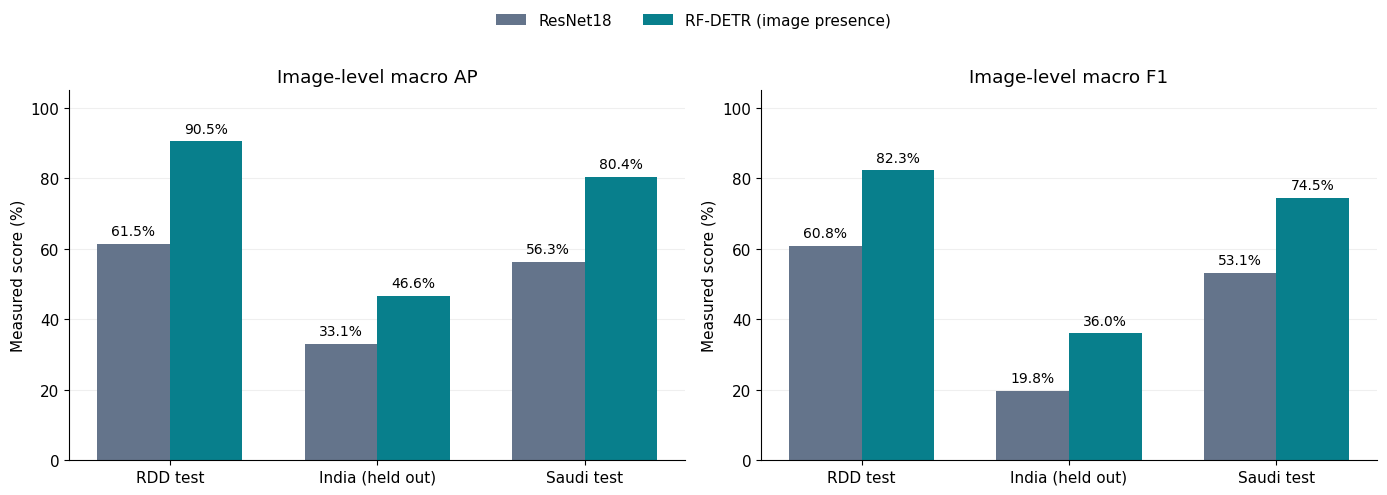

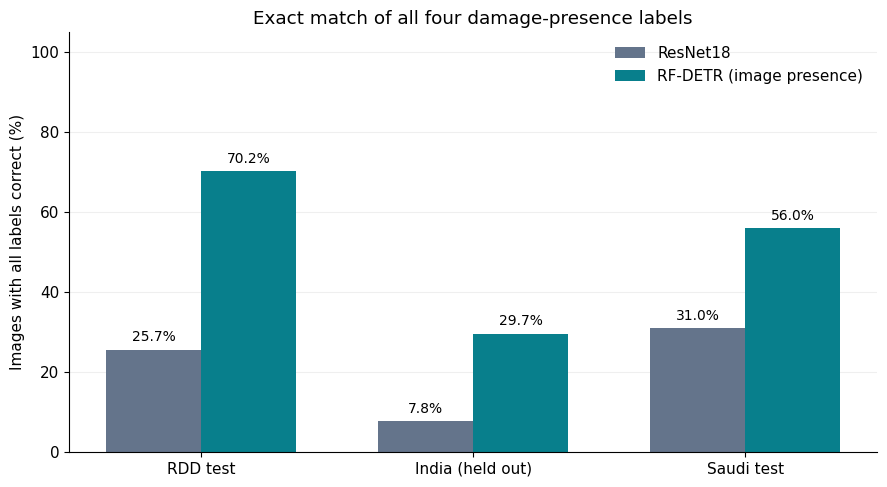

In [27]:

import numpy as np
import matplotlib.pyplot as plt

# Use the measured classifier–detector comparison.
models = [
    "ResNet18 classifier",
    "RF-DETR detector (image presence)",
]
model_labels = ["ResNet18", "RF-DETR (image presence)"]
splits = ["test", "held_country_test", "saudi_test"]
split_labels = ["RDD test", "India (held out)", "Saudi test"]
colors = ["#64748B", "#087F8C"]

data = comparison.copy()

if data.duplicated(["model", "split"]).any():
    raise ValueError("Duplicate model/split results.")

expected = {(model, split) for model in models for split in splits}
if not expected.issubset(set(zip(data["model"], data["split"]))):
    raise ValueError("Some model/split results are missing.")

def draw_comparison(ax, metric, title, ylabel):
    table = (
        data.pivot(index="split", columns="model", values=metric)
        .reindex(index=splits, columns=models) * 100
    )
    x = np.arange(len(splits))
    width = 0.35

    for i, model in enumerate(models):
        values = table[model].to_numpy()
        bars = ax.bar(
            x + (i - 0.5) * width,
            values,
            width,
            label=model_labels[i],
            color=colors[i],
        )
        ax.bar_label(
            bars,
            labels=[f"{value:.1f}%" for value in values],
            padding=4,
            fontsize=10,
        )

    ax.set(
        title=title,
        ylabel=ylabel,
        xticks=x,
        xticklabels=split_labels,
        ylim=(0, 105),
    )
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

# Compare image-level AP and F1 across test domains.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

draw_comparison(
    axes[0], "image_macro_AP",
    "Image-level macro AP", "Measured score (%)"
)
draw_comparison(
    axes[1], "image_macro_F1",
    "Image-level macro F1", "Measured score (%)"
)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="upper center", ncol=2, frameon=False
)
fig.tight_layout(rect=(0, 0, 1, 0.90))
plt.show()
plt.close(fig)

# Compare exact matches of all four damage-presence labels.
fig, ax = plt.subplots(figsize=(9, 5))

draw_comparison(
    ax, "image_exact_match",
    "Exact match of all four damage-presence labels",
    "Images with all labels correct (%)"
)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()
plt.close(fig)


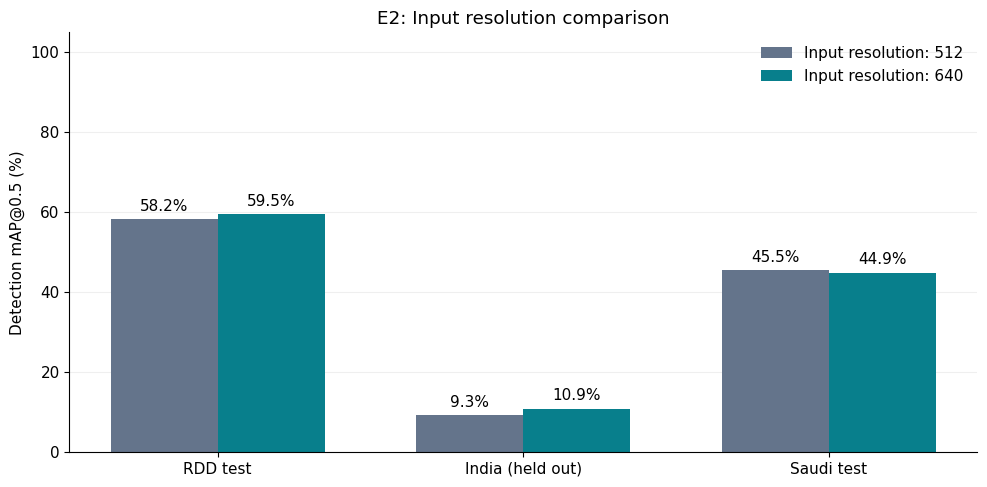

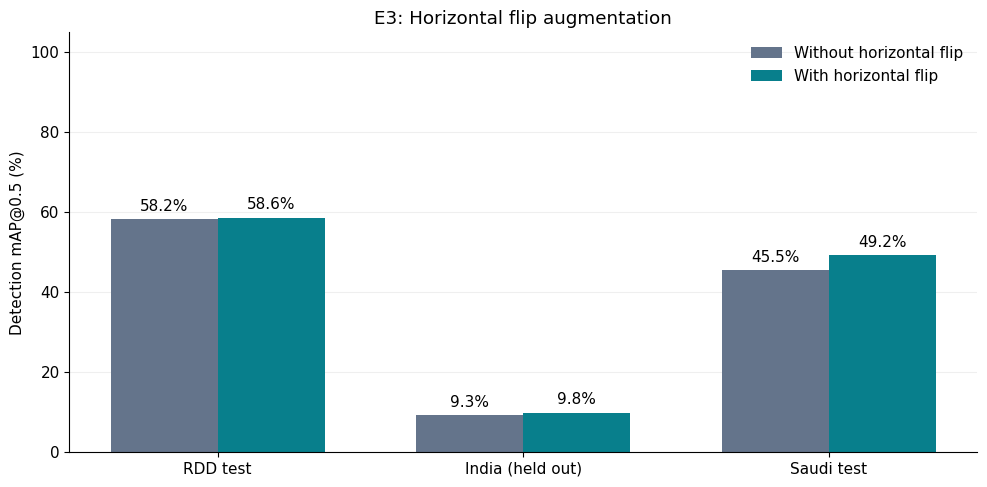

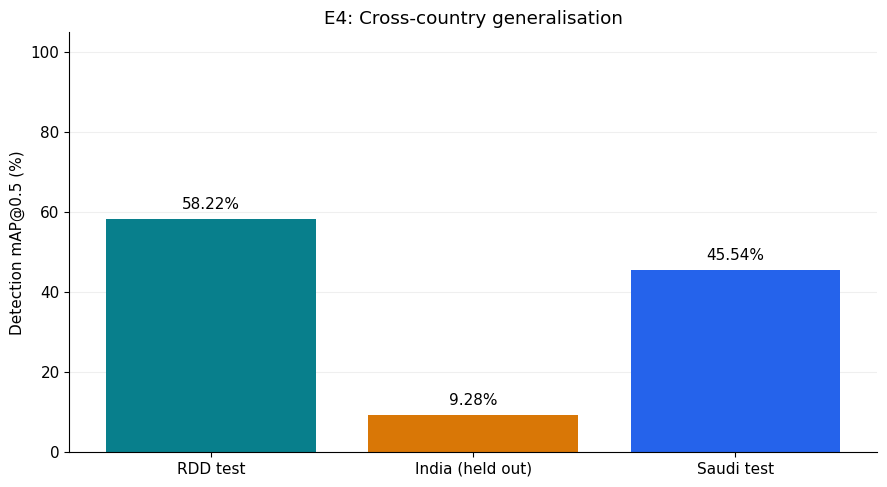

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

metrics_df = pd.DataFrame(ALL_METRICS)
test_splits = ["test", "held_country_test", "saudi_test"]
domain_labels = ["RDD test", "India (held out)", "Saudi test"]

def show_detector_comparison(run_names, labels, title):
    selected = metrics_df[
        metrics_df["run"].isin(run_names)
        & metrics_df["split"].isin(test_splits)
    ]

    table = selected.pivot(
        index="split", columns="run", values="mAP50"
    ).reindex(index=test_splits, columns=run_names) * 100

    if table.isna().any().any():
        raise ValueError(f"Missing evaluation results: {title}")

    fig, ax = plt.subplots(figsize=(10, 5))
    x = np.arange(len(test_splits))
    width = 0.35

    for i, name in enumerate(run_names):
        values = table[name].to_numpy()
        bars = ax.bar(
            x + (i - 0.5) * width,
            values, width,
            label=labels[i],
            color=["#64748B", "#087F8C"][i],
        )
        ax.bar_label(
            bars,
            labels=[f"{v:.1f}%" for v in values],
            padding=4,
        )

    ax.set(
        title=title,
        ylabel="Detection mAP@0.5 (%)",
        xticks=x,
        xticklabels=domain_labels,
        ylim=(0, 105),
    )
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
    ax.legend(frameon=False)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

# E2: Compare separately trained input resolutions.
show_detector_comparison(
    ["rf_small_512_noaug", "rf_small_640_noaug"],
    ["Input resolution: 512", "Input resolution: 640"],
    "E2: Input resolution comparison",
)

# E3: Compare training with and without horizontal flipping.
show_detector_comparison(
    ["rf_small_512_noaug", "rf_small_512_flip"],
    ["Without horizontal flip", "With horizontal flip"],
    "E3: Horizontal flip augmentation",
)

# E4: Display domain shift for the predefined baseline detector.
baseline = (
    metrics_df[metrics_df["run"] == "rf_small_512_noaug"]
    .set_index("split")
    .reindex(test_splits)
)
values = baseline["mAP50"].to_numpy() * 100

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(
    domain_labels, values,
    color=["#087F8C", "#D97706", "#2563EB"],
)
ax.bar_label(
    bars,
    labels=[f"{v:.2f}%" for v in values],
    padding=5,
)
ax.set(
    title="E4: Cross-country generalisation",
    ylabel="Detection mAP@0.5 (%)",
    ylim=(0, 105),
)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()
plt.close(fig)

## Priority and Weight Sensitivity
200 random variations controlled by seed and with ±20% accuracy for type weights, risk blending, and count.

Values ​​are geometric assumptions, and agreement with nomenclature is not a conservation expert's judgment.

In [30]:
priority_analysis(main_run,main_records)


,split,images,mean_priority,mean_annotation_priority,MAE,spearman,same_band
0,test,810,57.760621,63.063968,9.397183,0.781267,0.738272
1,held_country_test,1520,34.802034,73.118546,39.571926,0.151348,0.272368
2,saudi_test,100,61.882309,75.976001,14.858998,0.503213,0.610000


## E5 Image Representation Comparison for Duplication Detection
With one image per scene, there are no genuine positive examples of retrieving another scene with the same damage.

The file records this incomplete experiment and completes the export. It does not create pairs of modified images.

If available later, specify `DUPLICATE_PAIRS_CSV` with the following columns:
`image_a,image_b,label,split,group_a,group_b`.

`label=1` for the same physical damage in two different images; `0` for two different damages.

`split=validation` or `test`; the damage groups are separated.

The images must be damage crops with a known ID, not two images with the same damage class.

In [31]:
# No pair labels or repeat views are invented from classes, augmentation, or a single photograph.
e5_folder=RUN_ROOT/'E5_duplicate_embeddings';e5_folder.mkdir(exist_ok=True)
template=e5_folder/'duplicate_pairs_TEMPLATE.csv'
if not template.exists():
    pd.DataFrame(columns=['image_a','image_b','label','split','group_a','group_b']).to_csv(template,index=False)
if not DUPLICATE_PAIRS_CSV:
    E5_STATUS='not_evaluable_single_view_data'
    save_json(e5_folder/'status.json',dict(status=E5_STATUS,
        reason='Only one photograph per scene/defect. No independently labelled positive pairs of distinct views.',
        required='Different real photos of the same physical defect and different defects; disjoint validation/test defect IDs.',
        metrics_not_reported=['Recall@1','Recall@5','duplicate precision','duplicate recall','ROC AUC'],
        note='A different photograph of the same damage is necessary. Copying or augmenting one photo is not a substitute.'))
    print('E5: غير قابلة للتقييم بالصور الحالية؛ لم يتم اختلاق أزواج أو مقاييس.')
else:
    import imagehash
    from sklearn.metrics import precision_recall_fscore_support,roc_auc_score,roc_curve
    from transformers import AutoImageProcessor,AutoModel
    from torchvision import models
    f=Path(DUPLICATE_PAIRS_CSV).expanduser().resolve()
    pairs=pd.read_csv(f,dtype={'group_a':str,'group_b':str})
    required=['image_a','image_b','label','split','group_a','group_b']
    if not set(required)<=set(pairs) or pairs.empty or pairs[required].isna().any().any():raise ValueError('Incomplete labelled pair CSV')
    if set(pairs.split)!={'validation','test'} or not set(pairs.label)<={0,1}:raise ValueError('Invalid pair split/label')
    identity={};pixel_identity={};photo_pixels={}
    for side in ['a','b']:
        paths=[]
        for _,r in pairs.iterrows():
            p=Path(r['image_'+side]);p=(p if p.is_absolute() else f.parent/p).resolve(strict=True)
            key=str(p);group=str(r['group_'+side]).strip();tag=(group,r['split'])
            if not group:raise ValueError('Empty physical defect identity')
            if key in identity and identity[key]!=tag:raise ValueError('Photo identity/split conflict')
            identity[key]=tag
            with Image.open(p) as im:
                rgb=ImageOps.exif_transpose(im).convert('RGB');digest=hashlib.sha256(str(rgb.size).encode()+rgb.tobytes()).hexdigest()
            if digest in pixel_identity and pixel_identity[digest]!=tag:raise ValueError('Identical pixels cross identities/splits')
            pixel_identity[digest]=tag;photo_pixels[key]=digest;paths.append(key)
        pairs['image_'+side]=paths
    for _,r in pairs.iterrows():
        if r.image_a==r.image_b or int(r.label)!=int(r.group_a==r.group_b):raise ValueError('Self-pair or conflicting physical identity')
        if photo_pixels[r.image_a]==photo_pixels[r.image_b]:raise ValueError('Copies are not distinct views')
    val=pairs[pairs.split=='validation'];test=pairs[pairs.split=='test']
    if (set(val.group_a)|set(val.group_b))&(set(test.group_a)|set(test.group_b)):raise ValueError('Defect leakage between validation and test')
    for split,part in pairs.groupby('split'):
        if set(part.label)!={0,1}:raise ValueError(f'{split} needs positive and negative pairs')
    pairs=pairs.drop_duplicates(['image_a','image_b','split']).reset_index(drop=True)
    paths=sorted(set(pairs.image_a)|set(pairs.image_b));lookup={p:i for i,p in enumerate(paths)}
    def open_rgb(p):
        with Image.open(p) as im:return ImageOps.exif_transpose(im).convert('RGB')
    def normalize(x):return x/np.maximum(np.linalg.norm(x,axis=1,keepdims=True),1e-12)
    methods={'phash':np.vstack([np.asarray(imagehash.phash(open_rgb(p)).hash).ravel() for p in paths])}
    weights=models.ResNet18_Weights.IMAGENET1K_V1
    encoder=models.resnet18(weights=weights);encoder.fc=nn.Identity();encoder.to(DEVICE).eval()
    features=[]
    with torch.inference_mode():
        for start in range(0,len(paths),16):
            batch=torch.stack([weights.transforms()(open_rgb(p)) for p in paths[start:start+16]]).to(DEVICE)
            features.append(encoder(batch).cpu().numpy())
    methods['resnet18']=normalize(np.vstack(features));del encoder;gc.collect()
    processor=AutoImageProcessor.from_pretrained('facebook/dinov2-small')
    encoder=AutoModel.from_pretrained('facebook/dinov2-small').to(DEVICE).eval();features=[]
    with torch.inference_mode():
        for start in range(0,len(paths),16):
            inputs=processor(images=[open_rgb(p) for p in paths[start:start+16]],return_tensors='pt').to(DEVICE)
            features.append(encoder(**inputs).last_hidden_state[:,0].cpu().numpy())
    methods['dinov2']=normalize(np.vstack(features));del encoder;gc.collect()
    def similarity(name,features,a,b):
        return 1-np.mean(features[a]!=features[b],axis=-1) if name=='phash' else np.clip(np.sum(features[a]*features[b],axis=-1),-1,1)
    ia=pairs.image_a.map(lookup).to_numpy();ib=pairs.image_b.map(lookup).to_numpy();results=[];calibration={}
    fig,axes=plt.subplots(1,2,figsize=(10,4))
    for name,features in methods.items():
        scores=similarity(name,features,ia,ib);mask=(pairs.split=='validation').to_numpy()
        candidates=np.unique(np.r_[scores[mask],np.nextafter(scores[mask].max(),np.inf)])
        def choose(t):
            p,r,f1,_=precision_recall_fscore_support(pairs.loc[mask,'label'],scores[mask]>=t,average='binary',zero_division=0)
            return float(f1),float(p),float(t)
        threshold=max(map(choose,candidates))[2];calibration[name]=threshold
        for ax,split in zip(axes,['validation','test']):
            m=(pairs.split==split).to_numpy();part=pairs[m];y=part.label.to_numpy();z=scores[m]
            p,r,f1,_=precision_recall_fscore_support(y,z>=threshold,average='binary',zero_division=0)
            fpr,tpr,_=roc_curve(y,z);ax.plot(fpr,tpr,label=name)
            pd.DataFrame(dict(fpr=fpr,tpr=tpr)).to_csv(e5_folder/f'{name}_{split}_roc.csv',index=False)
            gallery=sorted(set(part.image_b));groups=dict(zip(part.image_b,part.group_b));recall1=[];recall5=[]
            for query,group in part[['image_a','group_a']].drop_duplicates().itertuples(index=False,name=None):
                pool=[p for p in gallery if p!=query];relevant=np.array([groups[p]==group for p in pool])
                if not relevant.any():continue
                z=similarity(name,features,np.full(len(pool),lookup[query]),np.array([lookup[p] for p in pool]))
                rank=np.argsort(-z,kind='stable')
                recall1.append(float(relevant[rank[:1]].sum()/relevant.sum()));recall5.append(float(relevant[rank[:5]].sum()/relevant.sum()))
            results.append(dict(method=name,split=split,pairs=len(part),threshold=threshold,precision=float(p),recall=float(r),F1=float(f1),ROC_AUC=float(roc_auc_score(y,scores[m])),
                Recall_at_1=float(np.mean(recall1)) if recall1 else None,Recall_at_5=float(np.mean(recall5)) if recall5 else None,eligible_queries=len(recall1)))
        pairs[name+'_similarity']=scores
    for ax,split in zip(axes,['validation','test']):ax.plot([0,1],[0,1],'k--');ax.set(title=split,xlabel='FPR',ylabel='TPR');ax.legend()
    fig.tight_layout();fig.savefig(e5_folder/'roc.png',dpi=150);plt.close(fig)
    pd.DataFrame(results).to_csv(e5_folder/'embedding_comparison.csv',index=False);pairs.to_csv(e5_folder/'pair_scores.csv',index=False)
    E5_STATUS='completed';save_json(e5_folder/'status.json',dict(status=E5_STATUS,thresholds=calibration,pairs_sha256=file_hash(f),
        scope='labelled damage crops supplied by user; frozen embeddings, not trained for 20 epochs; no GPS performance claim',
        retrieval='query=image_a; gallery=all unique image_b in split; exclude self; macro fraction of relevant images retrieved at K'))
    display(pd.DataFrame(results))


E5: غير قابلة للتقييم بالصور الحالية؛ لم يتم اختلاق أزواج أو مقاييس.


## Exporting Results and Requirements Status
CSV, JSON, PNG, Sample Images, and ZIP for results. `requirements_status.csv` clearly records missing requirements.

No cell converts a result of 15 to 20 by changing the title; the number is read from the actual checkpoint.

,run,split,images,completed_epochs,resolution,threshold,mAP50,mAP50_95,macro_precision,macro_recall,macro_F1,mAP50_gap_from_ID_percentage_points
1,rf_small_512_noaug,test,810,20,512,0.55,0.582235,0.290420,0.670340,0.547572,0.602411,0.000000
2,rf_small_512_noaug,held_country_test,1520,20,512,0.55,0.092837,0.033636,0.268475,0.108913,0.153760,-48.939835
3,rf_small_512_noaug,saudi_test,100,20,512,0.55,0.455409,0.216777,0.523905,0.455471,0.481586,-12.682644


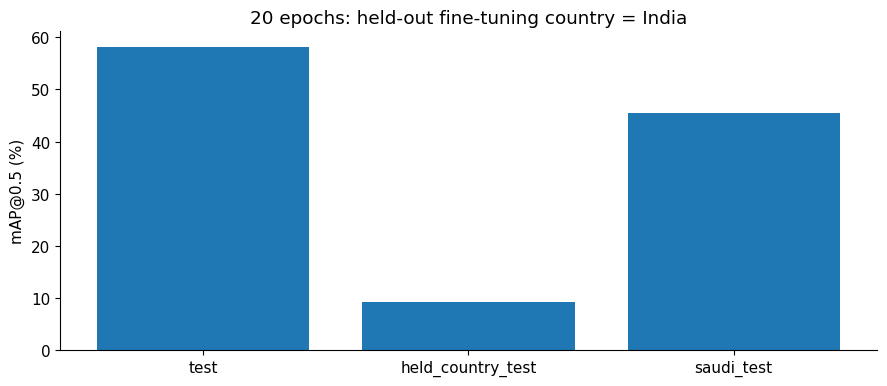

,requirement,status,evidence
0,E4 held-country and Saudi external test,completed,E4_domain_shift.csv
1,priority +/-20% sensitivity,completed,rf_small_512_noaug/priority_sensitivity_summar...
2,team-collected local photos,missing; Saudi public subset is not team-colle...,split_summary.csv
3,Saudi independent human label review,not confirmed,data_protocol.json
4,E1 classifier vs detector,completed,E1_classifier_vs_detector.csv
5,E2 input resolution,completed,E2_comparison.csv
6,E3 horizontal flip,completed,E3_comparison.csv
7,E5 duplicate embeddings,not_evaluable_single_view_data,E5_duplicate_embeddings/status.json
8,CPU inference latency,completed,all_cpu_latency.csv
9,live app end-to-end latency,not measured by this notebook; requires actual...,CPU timing covers the specified pipeline only


Results: /kaggle/working/RoadScan_20Epoch_Experiments/India_6f44f8600748
Download: /kaggle/working/RoadScan_20Epoch_Experiments/India_6f44f8600748_results.zip
Model checkpoints remain in their run folders; preserve them separately.


In [32]:
metrics=pd.DataFrame(ALL_METRICS);metrics.to_csv(RUN_ROOT/'all_detection_metrics.csv',index=False)
if CPU_METRICS:pd.DataFrame(CPU_METRICS).to_csv(RUN_ROOT/'all_cpu_latency.csv',index=False)
main=metrics[metrics.run=='rf_small_512_noaug']
reference=main[main.split=='test'].iloc[0]
shift=main[main.split.isin(['test','held_country_test','saudi_test','team_local_test'])].copy()
shift['mAP50_gap_from_ID_percentage_points']=100*(shift.mAP50-float(reference.mAP50))
shift.to_csv(RUN_ROOT/'E4_domain_shift.csv',index=False);display(shift)
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(shift.split,100*shift.mAP50);ax.set(ylabel='mAP@0.5 (%)',title=f'20 epochs: held-out fine-tuning country = {HELD_OUT_COUNTRY}')
fig.tight_layout();fig.savefig(RUN_ROOT/'E4_domain_shift.png',dpi=150);plt.show();plt.close(fig)
status=[dict(requirement='E4 held-country and Saudi external test',status='completed',evidence='E4_domain_shift.csv'),
    dict(requirement='priority +/-20% sensitivity',status='completed',evidence='rf_small_512_noaug/priority_sensitivity_summary.csv'),
    dict(requirement='team-collected local photos',status='completed' if SPLITS['team_local_test'] else 'missing; Saudi public subset is not team-collected',evidence='split_summary.csv'),
    dict(requirement='Saudi independent human label review',status='confirmed by user setting' if SAUDI_LABELS_HUMAN_VERIFIED else 'not confirmed',evidence='data_protocol.json')]
if 'comparison' in globals():
    status.append(dict(requirement='E1 classifier vs detector',status='completed',evidence='E1_classifier_vs_detector.csv'))
    for tag,name in [('E2 input resolution','rf_small_640_noaug'),('E3 horizontal flip','rf_small_512_flip')]:
        subset=metrics[metrics.run.isin(['rf_small_512_noaug',name])].copy()
        filename=tag.split()[0]+'_comparison.csv'
        if tag.startswith('E2') and CPU_METRICS:
            subset=subset.merge(pd.DataFrame(CPU_METRICS)[['run','mean_model_seconds','p95_model_seconds']],on='run',how='left')
        subset.to_csv(RUN_ROOT/filename,index=False)
        status.append(dict(requirement=tag,status='completed',evidence=filename))
    status.append(dict(requirement='E5 duplicate embeddings',status=E5_STATUS,evidence='E5_duplicate_embeddings/status.json'))
status.append(dict(requirement='CPU inference latency',status='completed' if CPU_METRICS else 'not measured',evidence='all_cpu_latency.csv'))
status.append(dict(requirement='live app end-to-end latency',status='not measured by this notebook; requires actual app session',evidence='CPU timing covers the specified pipeline only'))
pd.DataFrame(status).to_csv(RUN_ROOT/'requirements_status.csv',index=False);display(pd.DataFrame(status))
save_json(RUN_ROOT/'results_summary.json',dict(completed_training_epochs=EPOCHS,held_out_country=HELD_OUT_COUNTRY,
    split_sha256=SPLIT_HASH,runs=metrics.run.unique().tolist(),metrics=metrics.to_dict('records'),requirements=status))
notes=['# RoadScan experiment interpretation', '',
    f'Held-out country: {HELD_OUT_COUNTRY}. All detector results use final non-EMA weights after exactly 20 completed epochs.',
    'The country is excluded from RoadScan fine-tuning and validation; its presence in original general-purpose pretraining is unknown.',
    'Thresholds are selected only on validation. Detection AP uses low-confidence raw predictions; P/R/F1 use the frozen operating threshold.',
    'E4: inspect E4_domain_shift.csv and per-class AP tables. Country differences combine scene, annotation and class-distribution differences; no causal isolation.',
    'Priority agreement compares the same heuristic applied to predicted and annotated boxes, not expert repair urgency.',
    'Saudi images are a public external subset with draft annotations unless independently human-verified. Team local set is separate.',
    'CPU measurements include the documented pipeline, not UI/network latency. One seed and one 20-epoch budget do not establish statistical significance.',
    'Scene group IDs and pHash are useful leakage screens, not proof of geographic independence. Review near_duplicate_pairs.csv.',
    'Horizontal flips preserve longitudinal/transverse orientation; vertical flips and 90-degree rotations are avoided because they distort road geometry or class semantics.']
if 'comparison' in globals():
    notes += ['E1: compare image-level AP and F1 on the same images; do not compare classifier AP directly to bounding-box mAP.',
        'E2: compare 512 vs 640 after separate 20-epoch training at each resolution; see CPU latency and per-class AP together.',
        'E3: compare no horizontal flip vs 50% horizontal flip; seed, resolution, split and all other settings match.',
        'E5: '+E5_STATUS+'. Do not claim duplicate retrieval accuracy from a single photo per defect.']
    for split in ['test','held_country_test','saudi_test','team_local_test']:
        part=comparison[comparison.split==split]
        if len(part)==2:
            clf=part[part.model=='ResNet18 classifier'].iloc[0]
            det=part[part.model=='RF-DETR detector (image presence)'].iloc[0]
            notes.append(f'E1 {split}: classifier image F1={clf.image_macro_F1:.4f}; detector image F1={det.image_macro_F1:.4f}; difference={100*(det.image_macro_F1-clf.image_macro_F1):+.2f} percentage points. Only the detector also returns locations.')
    for name,tag in [('rf_small_640_noaug','E2'),('rf_small_512_flip','E3')]:
        changed=metrics[(metrics.run==name)&(metrics.split=='test')].iloc[0]
        notes.append(f'{tag} in-distribution test: baseline mAP50={reference.mAP50:.4f}; changed mAP50={changed.mAP50:.4f}; difference={100*(changed.mAP50-reference.mAP50):+.2f} percentage points. Inspect validation and external splits before interpretation; this is one seed.')
(RUN_ROOT/'interpretation.md').write_text('\n\n'.join(notes),encoding='utf-8')
# Portable result package excludes image copies, prediction caches and model checkpoints to keep it small.
archive=RUN_ROOT.parent/(RUN_ROOT.name+'_results.zip')
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for p in sorted(RUN_ROOT.rglob('*')):
        if not p.is_file() or any(x in p.parts for x in ['coco_trainval','predictions']):continue
        if p.suffix.lower() in {'.csv','.json','.png','.md','.txt'}:z.write(p,p.relative_to(RUN_ROOT))
print('Results:',RUN_ROOT)
print('Download:',archive)
print('Model checkpoints remain in their run folders; preserve them separately.')


## Backup
Package saved weights and results for download.

In [33]:
from zipfile import ZipFile, ZIP_STORED
from IPython.display import FileLink

# Save checkpoints and results together for later sessions.
archive = Path('/kaggle/working/RoadScan_Experiment_Backup.zip')
with ZipFile(archive, 'w', compression=ZIP_STORED) as backup:
    for path in sorted(RUN_ROOT.rglob('*')):
        if path.is_file() and not {'predictions', 'coco_trainval'}.intersection(path.relative_to(RUN_ROOT).parts):
            backup.write(path, path.relative_to(RUN_ROOT.parent))
print('Backup ready:', archive)
display(FileLink(str(archive)))

Backup ready: /kaggle/working/RoadScan_Experiment_Backup.zip


/kaggle/working/RoadScan_Experiment_Backup.zip